# 2.1 · Rebuilding the ICE BofA US High Yield Index from its constituents

> **Needs:** the fixed income research cache from notebook 1.1 (the constituent files of `H0A0` and its official level).
>
> **Produces:** nothing stored: tables and charts only.

The first test of any dataset is whether it reproduces something known. Equity notebook 2.1 rebuilds the S&P 500
from its members; this one rebuilds the **ICE BofA US High Yield Index** (`H0A0`) from its bonds and compares it
with the index ICE publishes.

A market-value-weighted index earns, over month $t$,

$$R_t = \sum_i w_{i,t-1}\, r_{i,t}$$

where $w_{i,t-1}$ is bond $i$'s weight after the rebalance at the end of month $t-1$ and $r_{i,t}$ its total
return over month $t$ (price change plus accrued and paid interest). Both are in ICE's month-end files.

**One gap is built into the files.** The file of month end $t$ lists the index *after* that day's rebalance. A bond
that left the index at $t$ - it matured or was called, was upgraded to investment grade, or defaulted - is not in
it, so its return over its last month, $r_{i,t}$, is in no file. Each month therefore reports:

* **covered** - the share of the held weight whose return is known;
* **return** - the weighted return of that share, scaled up to the whole index: the bonds that left are assumed
  to have earned what the rest earned;
* **leavers** - the weight that left without a return.

That assumption is neutral on average but not in every month: defaults leave after large losses, upgrades after
gains. The comparison with the official index measures what it costs.

In [1]:
import pandas as pd
from IPython.display import display

from fixed_income_research.analytics import replication as rp
from fixed_income_research.data.cache import ResearchCache
from fixed_income_research.data.index_data import RATINGS, load_index_data
from research_core import charts
from research_core.analytics.performance.metrics import performance
from research_core.analytics.performance.tracking import TRACKING_FORMAT, calendar_years, tracking

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")

charts.style()
cache = ResearchCache()

INDEX = "H0A0"
MONTHS = 12  # the returns are monthly: twelve periods a year

data = load_index_data(cache, INDEX)
print(
    f"{data.weights.shape[1]:,} bonds have been in {INDEX}, {data.dates.min():%B %Y} to {data.dates.max():%B %Y}, "
    f"on {len(data.dates)} month ends; {int(data.weights.iloc[-1].notna().sum()):,} are in it now"
)

5,459 bonds have been in H0A0, January 2019 to July 2026, on 90 month ends; 1,890 are in it now


## Step 1 · How much of the index can be rebuilt

For each month, the share of the index's weight whose return the files hold. The rest left at the month-end
rebalance. A month whose previous month end has no file cannot be rebuilt at all and is left out.

88 months rebuilt; on average 1.9% of the index leaves each month (most: 4.3% in November 2023)


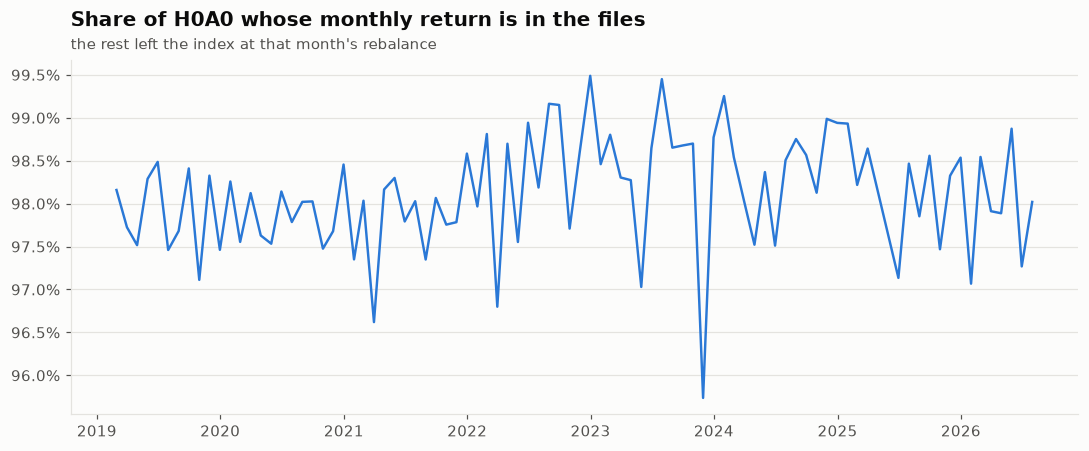

In [2]:
rebuilt = rp.index_returns(data.weights, data.total_returns)
fig = charts.lines(
    {"weight with a known return": rebuilt["covered"]},
    f"Share of {INDEX} whose monthly return is in the files",
    subtitle="the rest left the index at that month's rebalance",
    percent=True,
    decimals=1,
)
print(
    f"{len(rebuilt)} months rebuilt; on average {rebuilt['leavers'].mean():.1%} of the index leaves each month "
    f"(most: {rebuilt['leavers'].max():.1%} in {rebuilt['leavers'].idxmax():%B %Y})"
)

## Step 2 · Rebuilt against official

The official index is ICE's own total-return level (from FRED, which keeps its last three years), turned into
monthly returns. **Tracking error** is the annualised standard deviation of the monthly difference between the two;
**correlation** and **beta** come from regressing ours on theirs. A faithful rebuild has a tracking error of a few
hundredths of a percent and a beta of 1.

,months,ours_per_year,theirs_per_year,tracking_error,correlation,beta
rebuilt vs official,30,8.30%,8.15%,0.08%,0.9999,1.014


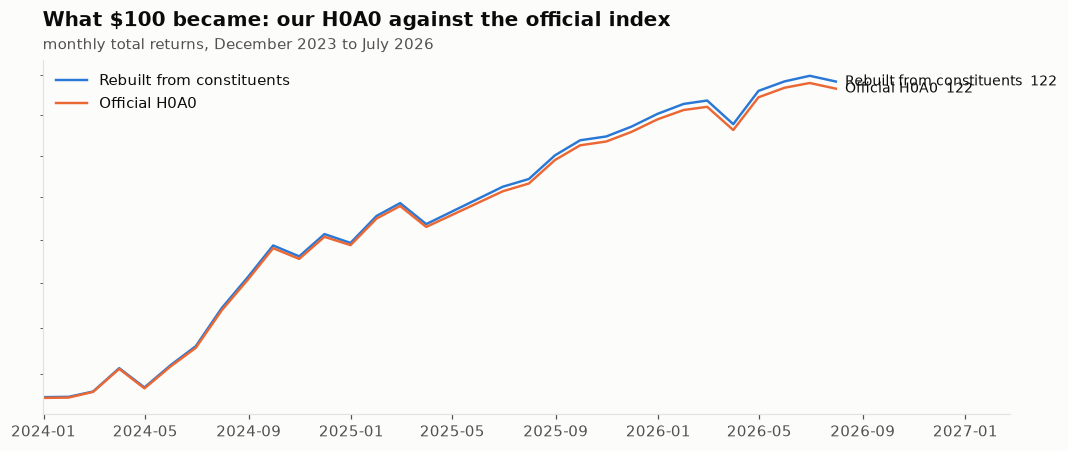

In [3]:
official = rp.official_returns(data.official)
both = pd.concat({"rebuilt": rebuilt["return"], "official": official}, axis=1).dropna()
fig = charts.growth(
    {"Rebuilt from constituents": both["rebuilt"], f"Official {INDEX}": both["official"]},
    f"What $100 became: our {INDEX} against the official index",
    subtitle=f"monthly total returns, {both.index.min():%B %Y} to {both.index.max():%B %Y}",
)
fit = tracking(both["rebuilt"], both["official"], periods_per_year=MONTHS)  # twelve monthly returns a year
summary = pd.DataFrame([fit], index=["rebuilt vs official"]).rename(columns={"days": "months"})
display(summary.style.format({k: v for k, v in TRACKING_FORMAT.items() if k in summary} | {"months": "{:,.0f}"}))

The monthly differences, in basis points, beside the weight that left that month: if the leavers explain the
gap, the months with the most weight leaving are the months furthest from the official return.

Gap: +1.2 bp a month on average; typical size 1.9 bp; largest 9.2 bp
Correlation of the gap with the weight that left: +0.44


as_of_date,2025-08-31 00:00:00,2025-09-30 00:00:00,2025-10-31 00:00:00,2025-11-30 00:00:00,2025-12-31 00:00:00,2026-01-31 00:00:00,2026-02-28 00:00:00,2026-03-31 00:00:00,2026-04-30 00:00:00,2026-05-31 00:00:00,2026-06-30 00:00:00,2026-07-31 00:00:00
rebuilt less official (bp),+0.9,+1.8,+0.1,+1.2,+1.1,+3.2,+1.1,-2.3,+3.0,-0.3,+4.3,-0.4
weight that left (%),+2.1,+1.4,+2.5,+1.7,+1.5,+2.9,+1.5,+2.1,+2.1,+1.1,+2.7,+2.0


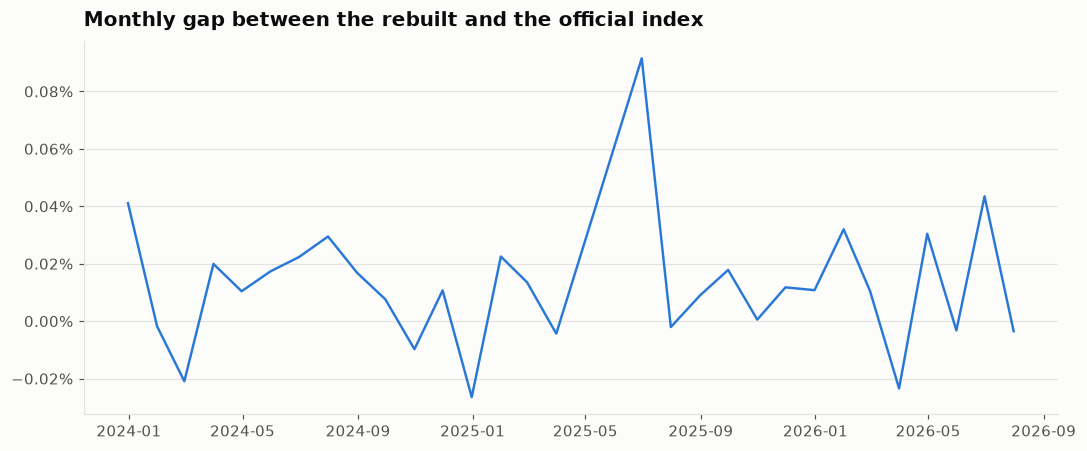

In [4]:
gap = ((both["rebuilt"] - both["official"]) * 1e4).rename("rebuilt less official (bp)")
detail = pd.concat([gap, (rebuilt["leavers"].reindex(both.index) * 100).rename("weight that left (%)")], axis=1)
fig = charts.lines(
    {"rebuilt less official": gap / 1e4},
    "Monthly gap between the rebuilt and the official index",
    percent=True,
    decimals=2,
)
print(
    f"Gap: {gap.mean():+.1f} bp a month on average; typical size {gap.abs().mean():.1f} bp; "
    f"largest {gap.abs().max():.1f} bp"
)
print(f"Correlation of the gap with the weight that left: {detail.corr().iloc[0, 1]:+.2f}")
display(detail.tail(12).T.style.format("{:+.1f}"))

## Step 3 · The whole history

The rebuilt index over every month the files cover - most of which FRED no longer serves - by calendar year.

,cagr,vol,sharpe,max_drawdown
Rebuilt,5.3%,8.1%,0.68,-15%


as_of_date,2019,2020,2021,2022,2023,2024,2025,2026
Rebuilt,9.5%,6.3%,5.4%,-11.3%,13.7%,8.3%,6.9%,1.7%


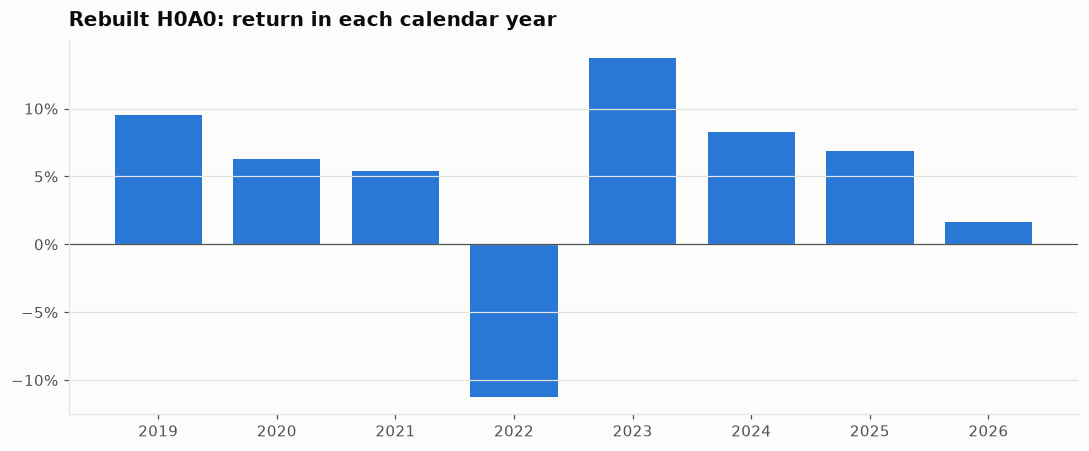

In [5]:
years = calendar_years({"Rebuilt": rebuilt["return"]})
fig = charts.yearly_bars(years, f"Rebuilt {INDEX}: return in each calendar year")
stats = pd.DataFrame({"Rebuilt": performance(rebuilt["return"], periods_per_year=MONTHS)}).T
display(stats.style.format({"cagr": "{:.1%}", "vol": "{:.1%}", "sharpe": "{:.2f}", "max_drawdown": "{:.0%}"}))
display(years.T.style.format("{:.1%}"))

## Step 4 · What the index is made of

A bond index is described by a few weighted averages - its yield, its spread over government bonds, its duration -
and by where its weight sits. All are computed here from the constituents, month by month.

* **OAS** is the market's price for the index's credit risk: it widens in a sell-off (March 2020) and narrows in
  calm markets.
* **Yield to worst** is what a buyer of the index earns if nothing defaults and issuers repay as early as suits them.
* **Duration** is its sensitivity to government yields; **spread duration** to its own spread.

as_of_date,2019-12-31 00:00:00,2020-12-31 00:00:00,2021-12-31 00:00:00,2022-12-31 00:00:00,2023-12-31 00:00:00,2024-12-31 00:00:00,2025-12-31 00:00:00,2026-12-31 00:00:00
OAS (bp),359.83,385.90,309.60,481.22,339.35,292.14,280.78,284.64
Yield to worst (%),5.41,4.24,4.32,8.98,7.69,7.47,6.63,7.42
Effective duration,3.30,3.67,4.04,4.04,3.31,3.22,2.87,3.08
Spread duration,3.04,3.53,3.76,3.97,3.17,3.10,2.78,2.99
Price,102.48,105.84,104.05,87.92,94.32,96.57,99.41,97.66
Coupon (%),6.29,6.01,5.68,5.80,6.15,6.50,6.65,6.71


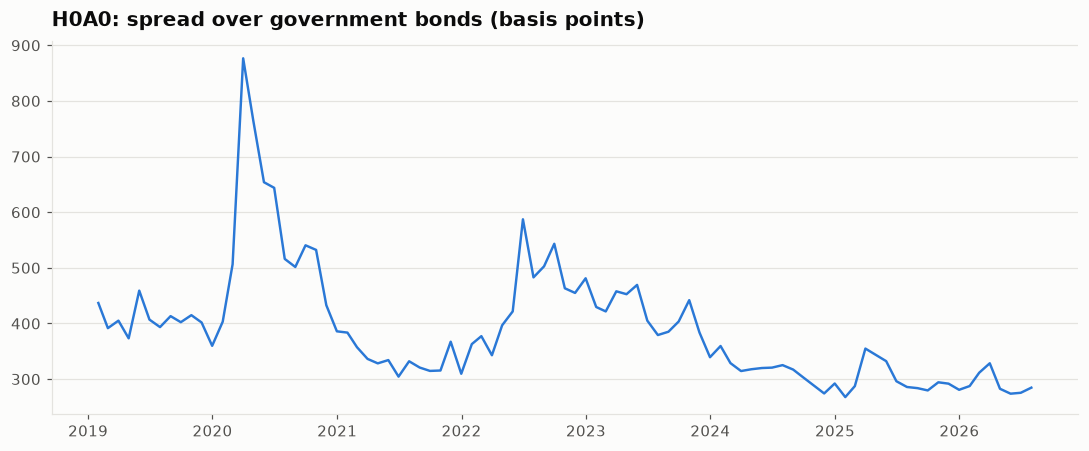

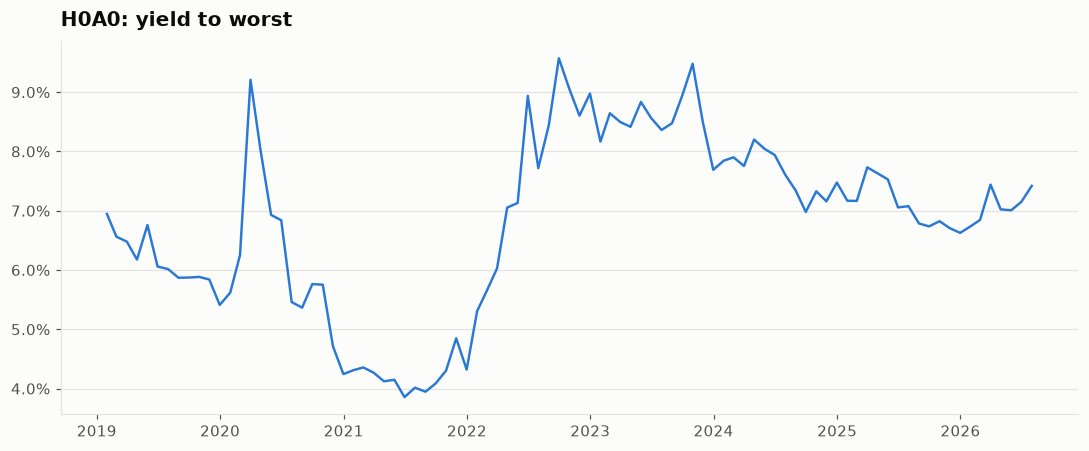

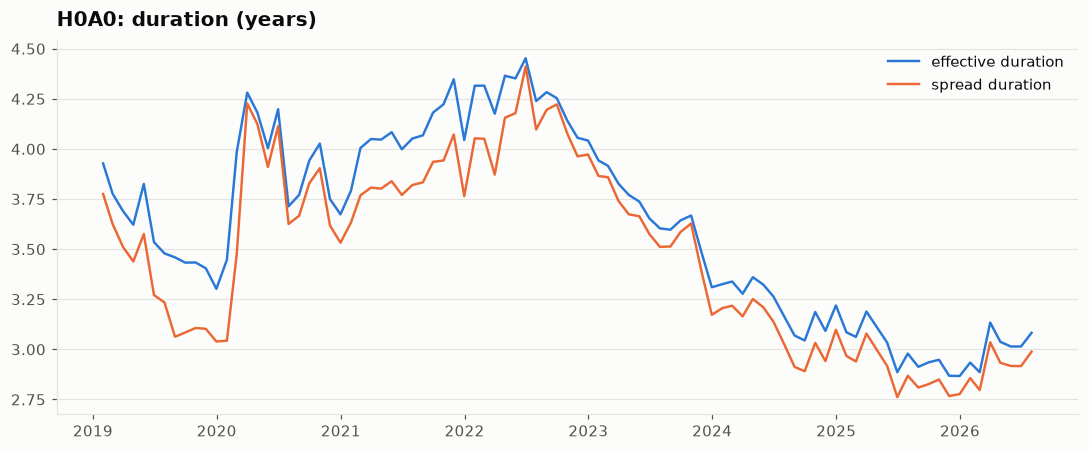

In [6]:
traits = pd.DataFrame(
    {
        "OAS (bp)": rp.weighted_average(data.weights, data.analytics["oas_bp"]),
        "Yield to worst (%)": rp.weighted_average(data.weights, data.analytics["yield_to_worst_pct"]),
        "Effective duration": rp.weighted_average(data.weights, data.analytics["effective_duration"]),
        "Spread duration": rp.weighted_average(data.weights, data.analytics["spread_duration"]),
        "Price": rp.weighted_average(data.weights, data.analytics["price"]),
        "Coupon (%)": rp.weighted_average(data.weights, data.analytics["coupon_pct"]),
    }
)
fig = charts.lines(
    {"option-adjusted spread": traits["OAS (bp)"]}, f"{INDEX}: spread over government bonds (basis points)"
)
fig = charts.lines(
    {"yield to worst": traits["Yield to worst (%)"] / 100}, f"{INDEX}: yield to worst", percent=True, decimals=1
)
fig = charts.lines(
    {"effective duration": traits["Effective duration"], "spread duration": traits["Spread duration"]},
    f"{INDEX}: duration (years)",
)
display(traits.resample("YE").last().T.style.format("{:,.2f}"))

The index by rating: ICE's composite ratings grouped into BB (the best of high yield), B, and CCC and below.

date,2019-01-31 00:00:00,2022-10-31 00:00:00,2026-07-31 00:00:00
BBB3,0.0%,0.0%,0.0%
BB1,14.7%,16.7%,14.2%
BB2,16.0%,13.1%,20.5%
BB3,17.0%,21.7%,25.7%
B1,13.8%,14.7%,10.5%
B2,13.1%,13.0%,11.7%
B3,13.6%,10.1%,9.3%
CCC1,6.0%,4.8%,3.5%
CCC2,3.7%,5.0%,3.5%
CCC3,1.3%,0.7%,1.0%


857 issuers; the ten largest hold 9.4% of the index


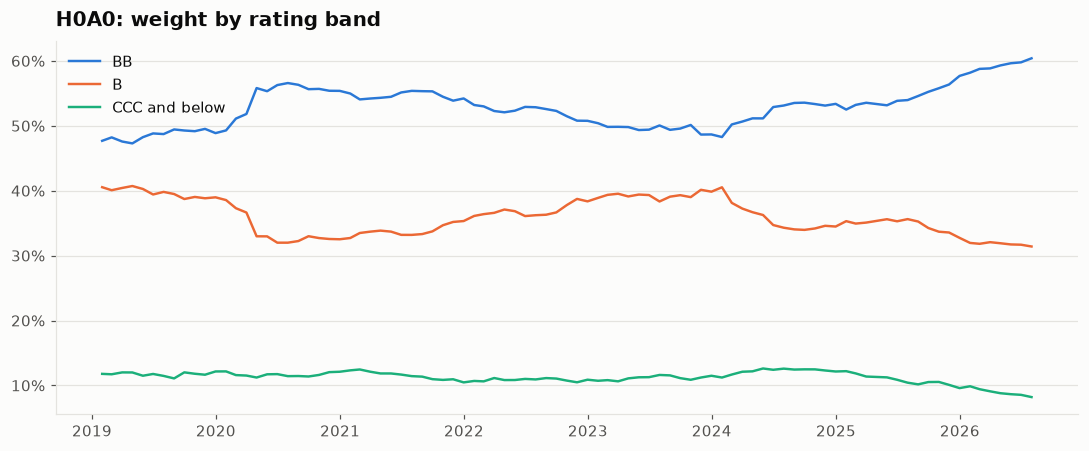

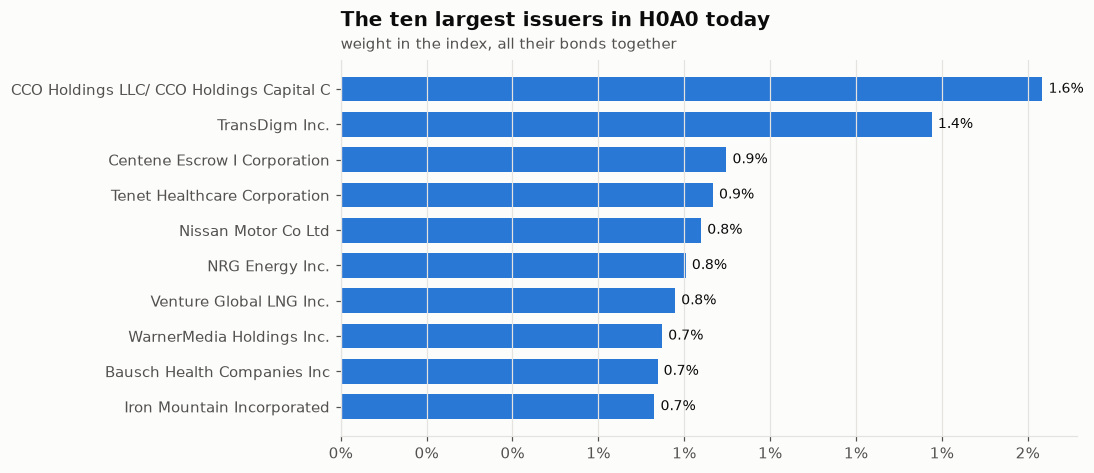

In [7]:
by_rating = rp.weight_by_group(data.weights, data.rating)
by_rating = by_rating[[r for r in RATINGS if r in by_rating.columns]]
bands = pd.DataFrame(
    {
        "BB": by_rating.filter(regex="^BB[123]$").sum(axis=1),
        "B": by_rating.filter(regex="^B[123]$").sum(axis=1),
        "CCC and below": by_rating.filter(regex="^(CCC|CC$|C$|D$)").sum(axis=1),
    }
)
fig = charts.lines({c: bands[c] for c in bands}, f"{INDEX}: weight by rating band", percent=True)
display(by_rating.iloc[[0, len(by_rating) // 2, -1]].T.style.format("{:.1%}"))
issuers = data.issuer.iloc[-1].where(data.weights.iloc[-1].notna())
largest = data.weights.iloc[-1].groupby(issuers).sum().nlargest(10)
names = cache.query("SELECT issuer_id, name FROM core.issuer").set_index("issuer_id")["name"]
fig = charts.ranked_bars(
    largest.rename(index=lambda i: names.get(int(i), str(i))[:40]),
    f"The ten largest issuers in {INDEX} today",
    subtitle="weight in the index, all their bonds together",
    percent=True,
)
print(f"{int(issuers.nunique()):,} issuers; the ten largest hold {largest.sum():.1%} of the index")

## Findings

Results as of the run below (90 month-end files of `H0A0`, January 2019 to July 2026; April 2025 has no file).

* **The files reproduce the index.** Over the 30 months that both exist (the official level reaches back three
  years), the rebuilt index returns 8.30 % a year against the official 8.15 %, with a tracking error of 0.08 % a
  year, a correlation of 0.9999 and a beta of 1.01. The typical monthly gap is 1.9 basis points, the largest 9.2.
* **The gap has a direction, and the leavers explain part of it.** The rebuilt index runs 1.2 basis points a month
  ahead of the official one, and the gap rises with the weight that left that month (correlation +0.44): on
  average 1.9 % of the index leaves at each rebalance (4.3 % in November 2023) and its last month's return is in
  no file. Assuming those bonds earned what the rest earned flatters the index slightly, as expected of a market
  where the bonds that leave after losses (defaults) lose more than those that leave after gains (upgrades) gain.
* **88 of 90 months can be rebuilt**: January 2019 has no month before it, and April 2025's missing file costs
  April and May 2025. Over those months the rebuilt index earned 5.3 % a year at 8.1 % volatility, with a worst
  fall of 15 %; 2022 (-11.3 %) and 2023 (+13.7 %) are its extremes.
* **What it is made of.** 5,459 bonds have been members; 1,890 are today, from 857 issuers, the ten largest
  holding 9.4 % of the index. Its spread over government bonds ended 2022 at 481 basis points and stood at 285 in
  July 2026; its yield to worst rose from 4.2 % at the end of 2020 to 9.0 % at the end of 2022. Effective duration
  fell from about 4 years in 2021-2022 to about 3. The index has moved up in quality: BB-rated bonds were 48 % of
  it in January 2019 and are 60 % now, CCC and below 12 % then and 8 % now.

## Limits

* **The leavers' last month.** The rebuilt return assumes the bonds that left earned what the rest earned. The
  constituent file taken *before* the rebalance (the same day's "current" universe rather than next month's) would
  close the gap; it is not among the files loaded.
* **The official level reaches back three years only** (FRED's limit for ICE's series), so the comparison covers
  those years; earlier months are rebuilt but not checked. Loading the level every month extends the comparison
  forward.
* **A missing month end** leaves two months without a rebuilt return: its own, and the one after it, whose
  starting weights it holds.

## Glossary

* **Total return** - price change plus interest, accrued and paid, over the period.
* **Tracking error** - the annualised standard deviation of the difference between two return series.
* **Basis point (bp)** - one hundredth of a percent.
* **Option-adjusted spread, duration, rating** - see notebook 1.1's glossary.